## 04 - Multi-Model Comparisons

Notebook with all data of four models: qwen, llama, gemma and mistral.


In [25]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({
    'figure.dpi': 150, 
    'axes.spines.top': False, 
    'axes.spines.right': False,
    'font.size': 11,
    'axes.titlesize': 14
})

MODELS = ['Qwen 2.5:7B', 'Gemma 2:2B', 'LLaMA 3.2:3B', 'Mistral 7B', "Phi3:mini"]
RESULTS_DIR = Path("../results")
model_folders = ["qwen", "gemma", "llama", "mistral", "phi3"]

for folder in model_folders:
    folder_path = RESULTS_DIR / folder
    if folder_path.exists():
        files = len(os.listdir(folder_path))
        print(f"[{folder}]: Found directory with {files} files.")
    else:
        print(f"[{folder}]: Directory not found, waiting for file transfer.")
print("-" * 30)


data = {
    'Model': MODELS,
    'Single_Justified': [89.7, 74.0, 78.3, 74.7, 85.3],
    'Self_Revision': [81.3, 54.7, 56.7, 68.0, 72.3],
    'Vote_at_3': [90.7, 73.3, 78.7, 78.0, 87.3],
    'Unrestr_Vote': [88.3, 70.0, 75.0, 77.0, 78.0],
    'Unrestr_Judge': [88.0, 67.0, 71.3, 75.0, 60.0],
    'Struct_Vote': [90.3, 70.7, 78.3, 78.3, 56.0],
    'Struct_Change_Rate': [1.8, 12.0, 7.0, 11.0, 40.4],
    'Qual_Peer_Pressure': [3, 2, 4, 1, 3],
    'Qual_Specific_Wrong': [4, 6, 4, 7, 5]
}

df = pd.DataFrame(data).set_index('Model')
print("Master DataFrame loaded successfully!")
display(df.head())


[qwen]: Found directory with 4 files.
[gemma]: Found directory with 4 files.
[llama]: Found directory with 4 files.
[mistral]: Found directory with 4 files.
[phi3]: Found directory with 4 files.
------------------------------
Master DataFrame loaded successfully!


,Single_Justified,Self_Revision,Vote_at_3,Unrestr_Vote,Unrestr_Judge,Struct_Vote,Struct_Change_Rate,Qual_Peer_Pressure,Qual_Specific_Wrong
Model,,,,,,,,,
Qwen 2.5:7B,89.7,81.3,90.7,88.3,88.0,90.3,1.8,3,4
Gemma 2:2B,74.0,54.7,73.3,70.0,67.0,70.7,12.0,2,6
LLaMA 3.2:3B,78.3,56.7,78.7,75.0,71.3,78.3,7.0,4,4
Mistral 7B,74.7,68.0,78.0,77.0,75.0,78.3,11.0,1,7
Phi3:mini,85.3,72.3,87.3,78.0,60.0,56.0,40.4,3,5


### 1. Voting vs. Debate by Models
Comparing the accuracy of Independent Vote@3 vs. Structured Debate across all four models to answer our core research question.

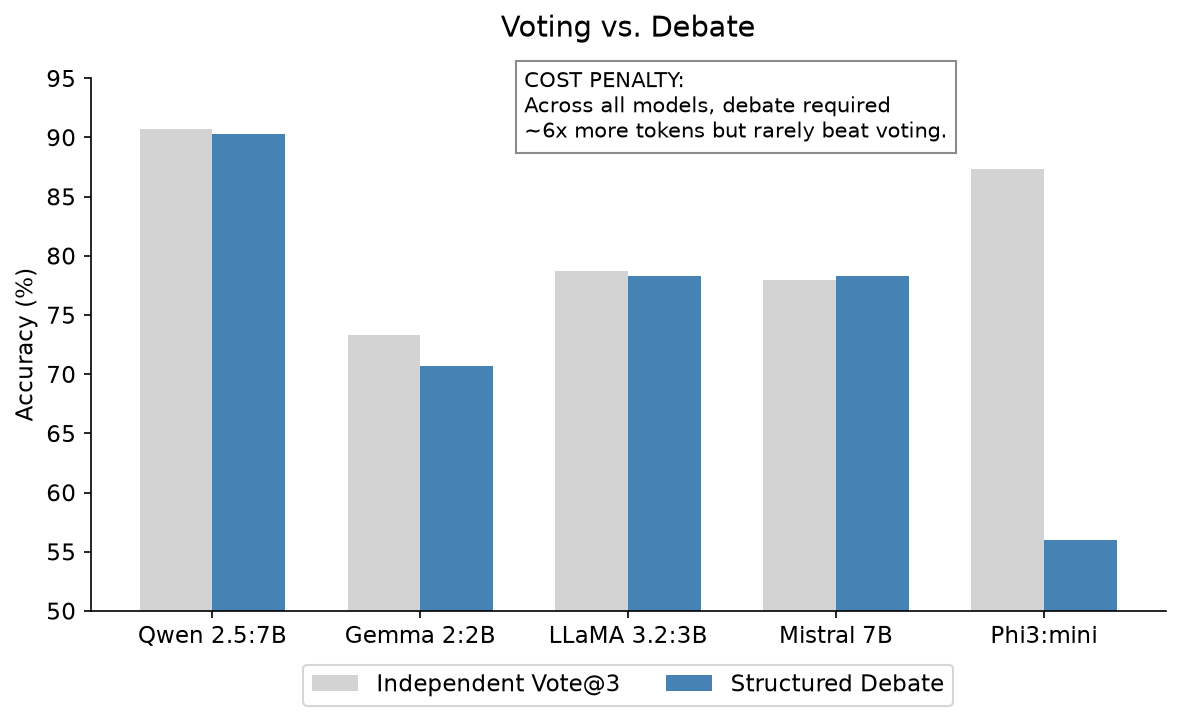

In [26]:
x = np.arange(len(df))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, df['Vote_at_3'], width, label='Independent Vote@3', color='lightgray')
rects2 = ax.bar(x + width/2, df['Struct_Vote'], width, label='Structured Debate', color='steelblue')

ax.set_ylabel('Accuracy (%)')
ax.set_title('Voting vs. Debate', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(df.index)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2)

ax.set_ylim(50, 95) 

ax.text(1.5, 90, "COST PENALTY:\nAcross all models, debate required\n~6x more tokens but rarely beat voting.", 
        fontsize=10, bbox=dict(facecolor='white', alpha=0.9, edgecolor='gray'))

plt.tight_layout()
plt.show()

### 2. Free vs. Structured
Tracking how models react to being constrained by the structured debate protocol. 

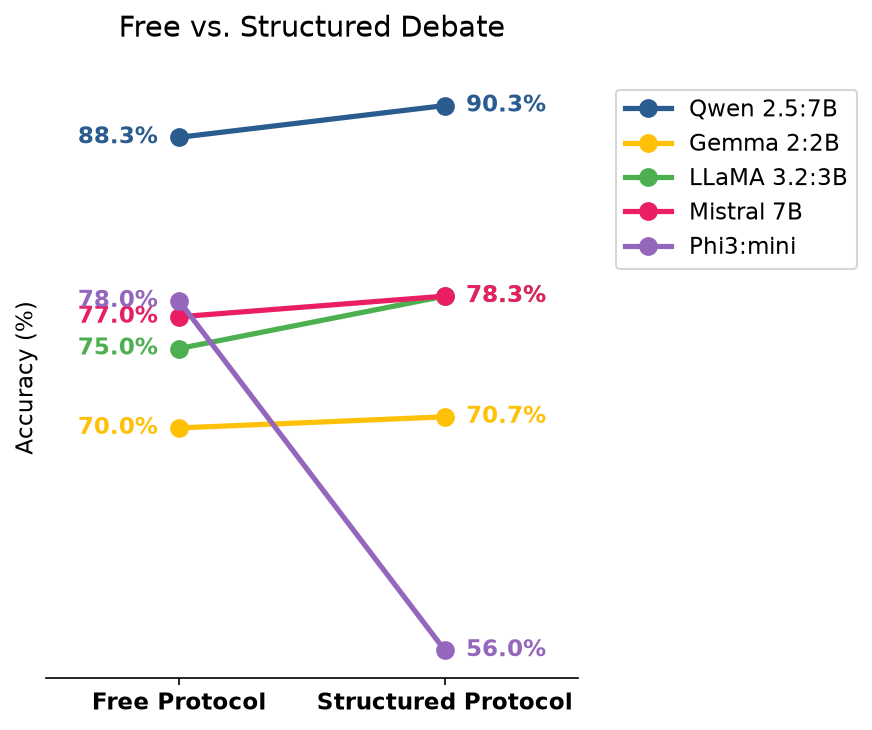

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = ['#2b5c8f', '#FFC107', '#4CAF50', '#E91E63', '#9467bd']

for i, model in enumerate(df.index):
    y_free = df.loc[model, 'Unrestr_Vote']
    y_struct = df.loc[model, 'Struct_Vote']
    
    ax.plot([1, 2], [y_free, y_struct], marker='o', markersize=8, 
            label=model, linewidth=2.5, color=colors[i])
    
    ax.text(0.92, y_free, f"{y_free}%", ha='right', va='center', color=colors[i], fontweight='bold')
    ax.text(2.08, y_struct, f"{y_struct}%", ha='left', va='center', color=colors[i], fontweight='bold')

ax.set_xticks([1, 2])
ax.set_xticklabels(['Free Protocol', 'Structured Protocol'], fontweight='bold')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Free vs. Structured Debate', pad=20)
ax.set_xlim(0.5, 2.5)

ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', left=False, labelleft=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

### 3. Unsupported Persuasion Analysis
Analyzing behavior under `unsupported_persuasion`: Does the model hallucinate fake science (Specific but Wrong) or quietly cave to the group (Peer Pressure)?

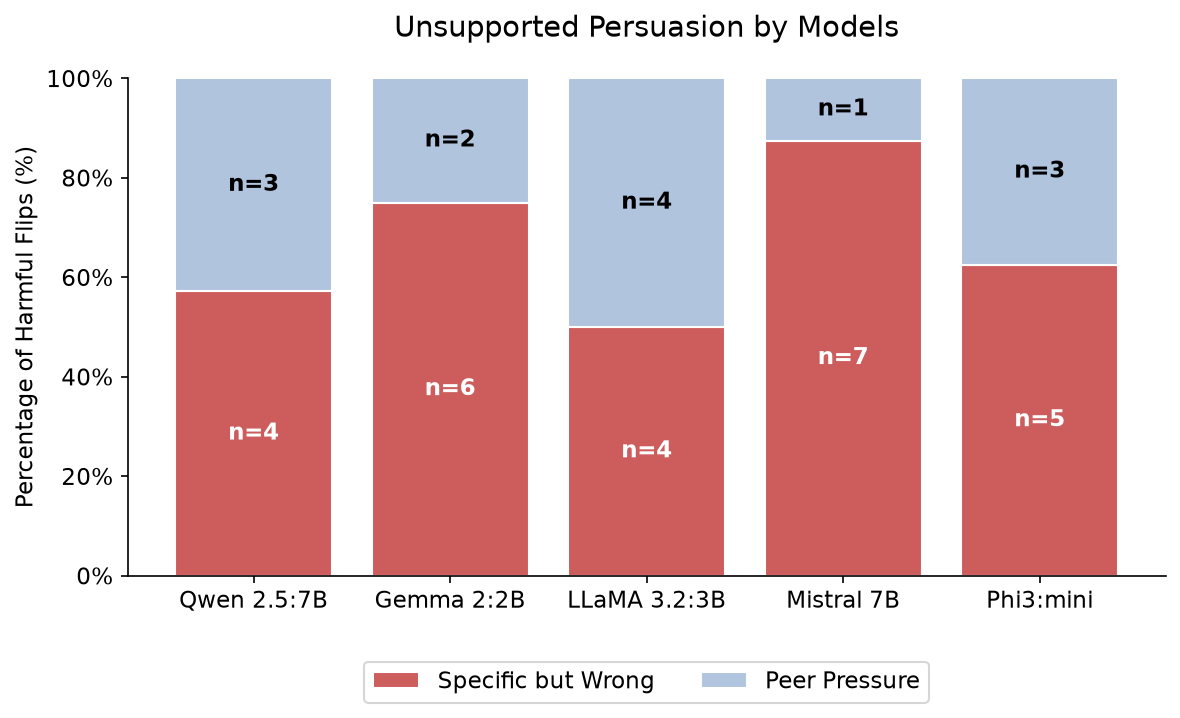

In [28]:
totals = df['Qual_Peer_Pressure'] + df['Qual_Specific_Wrong']
pp_pct = (df['Qual_Peer_Pressure'] / totals) * 100
sbw_pct = (df['Qual_Specific_Wrong'] / totals) * 100

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(df.index, sbw_pct, color='indianred', edgecolor='white', label='Specific but Wrong')
ax.bar(df.index, pp_pct, bottom=sbw_pct, color='lightsteelblue', edgecolor='white', label='Peer Pressure')

ax.set_ylabel('Percentage of Harmful Flips (%)')
ax.set_title('Unsupported Persuasion by Models', pad=20)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

for i, model in enumerate(df.index):
    if sbw_pct.iloc[i] > 5:
        ax.text(i, sbw_pct.iloc[i]/2, f"n={df['Qual_Specific_Wrong'].iloc[i]}", ha='center', va='center', color='white', fontweight='bold')
    if pp_pct.iloc[i] > 5:
        ax.text(i, sbw_pct.iloc[i] + pp_pct.iloc[i]/2, f"n={df['Qual_Peer_Pressure'].iloc[i]}", ha='center', va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

### 4. The "Self-Sabotage" Effect
What happens when an agent debates itself without external peers? This chart compares Single Agent baseline vs. 2 rounds of Self-Revision.

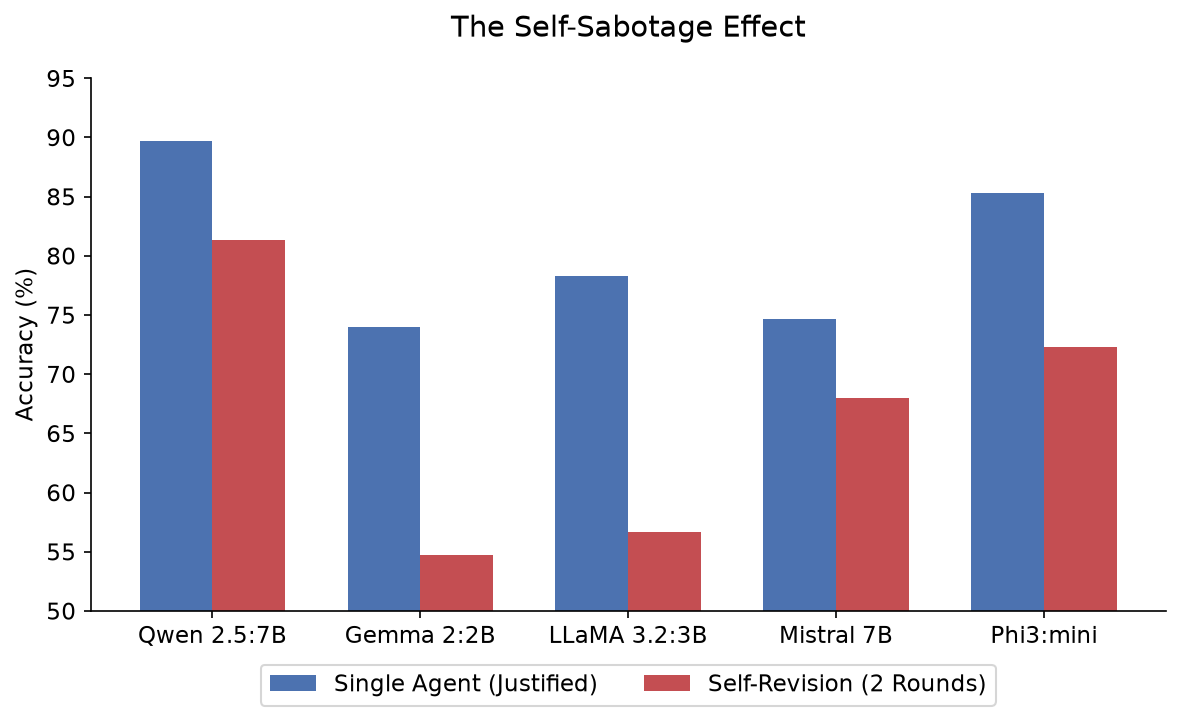

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(df))

ax.bar(x - width/2, df['Single_Justified'], width, label='Single Agent (Justified)', color='#4c72b0')
ax.bar(x + width/2, df['Self_Revision'], width, label='Self-Revision (2 Rounds)', color='#c44e52')

ax.set_ylabel('Accuracy (%)')
ax.set_title('The Self-Sabotage Effect', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(df.index)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_ylim(50, 95)

plt.tight_layout()
plt.show()


### 5. The "Judge Penalty"
Evaluating whether using an independent LLM Judge improves outcomes over a simple mathematical Majority Vote.

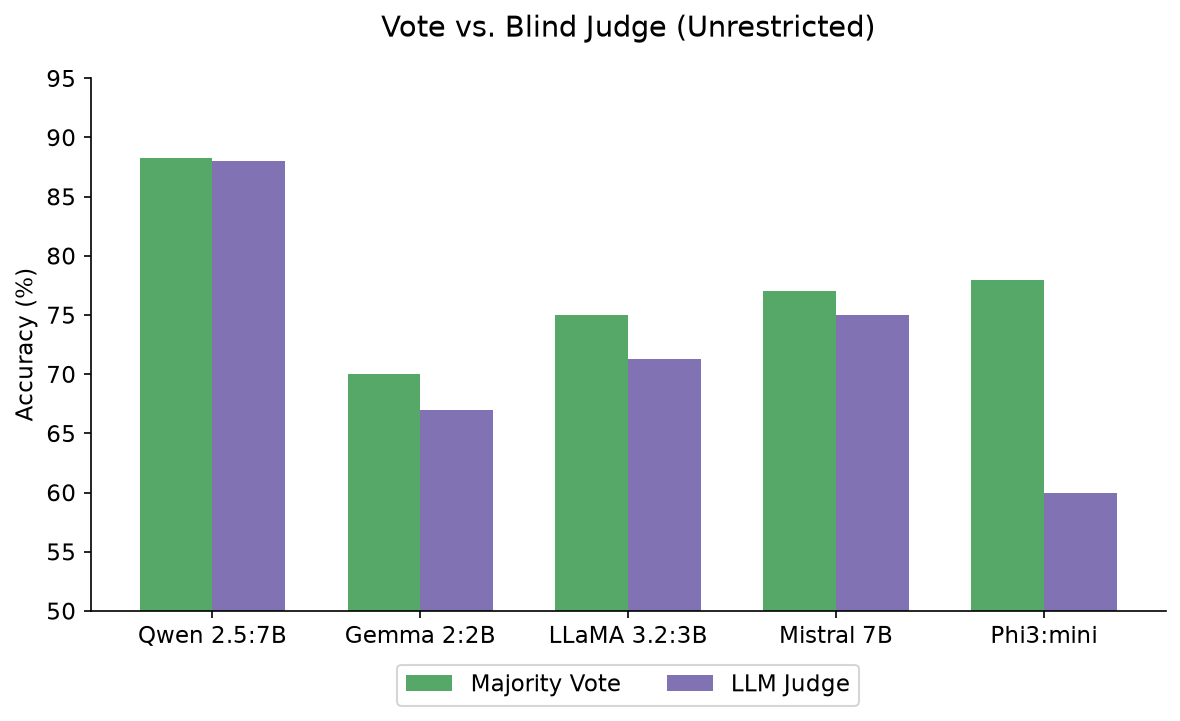

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(df))

ax.bar(x - width/2, df['Unrestr_Vote'], width, label='Majority Vote', color='#55a868')
ax.bar(x + width/2, df['Unrestr_Judge'], width, label='LLM Judge', color='#8172b3')

ax.set_ylabel('Accuracy (%)')
ax.set_title('Vote vs. Blind Judge (Unrestricted)', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(df.index)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_ylim(50, 95)

plt.tight_layout()
plt.show()

### 6. Model "Stubbornness"
How often does each model actually flip its answer during a structured debate?

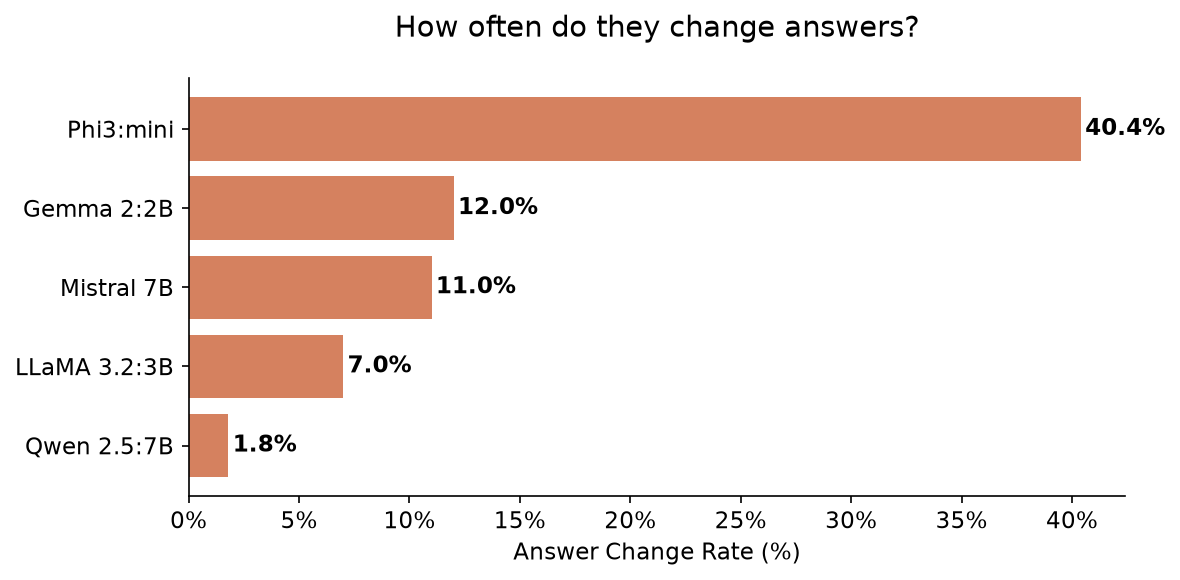

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))

df_sorted = df.sort_values(by='Struct_Change_Rate', ascending=True)

bars = ax.barh(df_sorted.index, df_sorted['Struct_Change_Rate'], color='#d5815f')

ax.set_xlabel('Answer Change Rate (%)')
ax.set_title('How often do they change answers?', pad=20)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.2, bar.get_y() + bar.get_height()/2, f'{width}%', 
            ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()
